In [14]:
import torch
import math
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

words = open('names.txt', 'r').read().splitlines()
words[:10]

chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
vocab_size = len(itos) # 27

block_size = 3 
X, Y = [], []
for word in words:
    context = [0] * block_size 
    for ch in word + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        context = context[1:] + [ix] 
X = torch.tensor(X) 
Y = torch.tensor(Y) 

In [15]:
# build the dataset

def build_dataset(words):
    block_size = 3
    X, Y = [], [] 
    for word in words:
        # print(word)
        context = [0] * block_size 
        for ch in word + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '------>', itos[ix])
            context = context[1:] + [ix] 
    X = torch.tensor(X) 
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1]) # 80%
Xdev, Ydev = build_dataset(words[n1: n2]) # 10%
Xts, Yts = build_dataset(words[n2:]) # 10%

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


# what we had

In [20]:
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embd),               generator = g)
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g) 
b1 = torch.randn(n_hidden,                          generator = g)
W2 = torch.randn((n_hidden, vocab_size),            generator = g)
b2 = torch.randn(vocab_size,                        generator = g)
parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
    p.requires_grad = True

11897


In [21]:
# hyperparameters
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construction
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X, Y

    # forward pass
    emb = C[Xb] # embed the characters into vectors
    embcat = emb.view(emb.shape[0], -1) # concatenate the embedding vectors
    hpreact = embcat @ W1 + b1 # hidden layer pre-activation
    h = torch.tanh(hpreact) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss function

    # back propogation
    for parameter in parameters:
        parameter.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for parameter in parameters:
        parameter.data -= lr * parameter.grad

    # tract stats
    if i == 0:
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    if (i+1) % 10000 == 0: # print loss function value once in a while
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

      1/ 200000: 27.8817
  10000/ 200000: 2.7073
  20000/ 200000: 2.0407
  30000/ 200000: 2.3638
  40000/ 200000: 2.2808
  50000/ 200000: 2.4303
  60000/ 200000: 1.7856
  70000/ 200000: 1.9982
  80000/ 200000: 2.4749
  90000/ 200000: 2.2837
 100000/ 200000: 1.9924
 110000/ 200000: 2.0996
 120000/ 200000: 2.1612
 130000/ 200000: 2.1826
 140000/ 200000: 1.9403
 150000/ 200000: 2.4570
 160000/ 200000: 2.1866
 170000/ 200000: 1.7776
 180000/ 200000: 1.6747
 190000/ 200000: 2.1325
 200000/ 200000: 2.4201


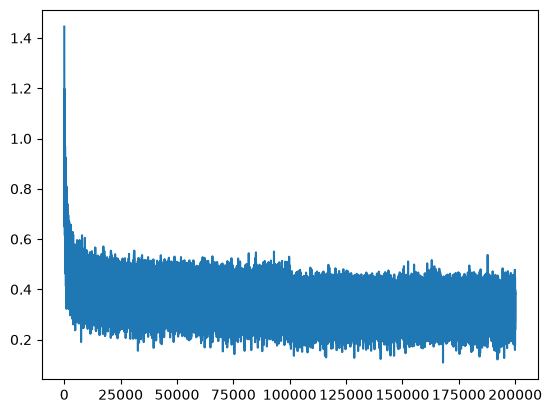

In [22]:
plt.plot(lossi)

In [23]:
@torch.no_grad() # this decorator disables gradient tracking

def split_loss(split): # split is either train, val, or test
    x, y = {
        'train': [Xtr, Ytr],
        'val': [Xdev, Ydev],
        'test': [Xts, Yts],
    }[split]
    emb = C[x] # (N, block_size, n_embd)
    embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
    h = torch.tanh(embcat @ W1 + b1) # (N, n_hidden)
    logits = h @ W2 + b2 # (N, voacb_size)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')
    

train 2.1264491081237793
val 2.169877767562866


In [24]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):

    out = []
    context = [0] * block_size
    while True:
        # forward pass the neural net
        emb = C[torch.tensor([context])] # (1, block_size, n_embd)
        h = torch.tanh(emb.view(1, -1) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1) 
        # sample from the distribution
        ix = torch.multinomial(probs, num_samples = 1, generator = g).item()
        # shift the context window and track the samples
        context = context[1:] + [ix]
        out.append(ix)
        # if we sample the special '.' token, break
        if ix == 0:
            break

    print(''.join(itos[ix] for ix in out)) # decode and print the generated word


carlah.
amorie.
khirmin.
rey.
cassanden.
jazhubedah.
sart.
kaeli.
nellara.
chaiir.
kaleigh.
ham.
jore.
quinn.
salin.
alianni.
wazthoniearyxi.
jace.
pirran.
eddeci.


# first issue: great loss function upon initialization

In [ ]:
# expected loss function value upon initialization
-torch.tensor(1/27.0).log()

tensor(3.2958)

which is far from the value we have: about 27

In [33]:
# 4-dimensional example of the issue
logits = torch.tensor([0.0, 0.0, 0.0, 0.0])
probs = torch.softmax(logits, dim=0)
loss = -probs.log().mean()
print(logits, probs, loss)

logits = torch.randn(4) * 10
probs = torch.softmax(logits, dim=0)
loss = -probs.log().mean()
print(logits, probs, loss)

tensor([0., 0., 0., 0.]) tensor([0.2500, 0.2500, 0.2500, 0.2500]) tensor(1.3863)
tensor([ -1.9560, -10.5334,   8.2636,  -9.5486]) tensor([3.6448e-05, 6.8637e-09, 9.9996e-01, 1.8376e-08]) tensor(11.7072)


in other words, the problem is that the value of logits upon initialization deviates too much from 0, and we need to change the value of logits upon initialization so that the value is closer to zero. 

Since we want a logits that is close to zero, we scale down the value of W2 and b2: we multiply W2 by 0.01, and set b2 simply to 0. 

The reason why we do not want the value of W2 to be completely zero is that 

In [39]:
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embd),               generator = g)
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g) 
b1 = torch.randn(n_hidden,                          generator = g)
W2 = torch.randn((n_hidden, vocab_size),            generator = g) * 0.01
b2 = torch.randn(vocab_size,                        generator = g) * 0
parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
    p.requires_grad = True

11897


In [40]:
# hyperparameters
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construction
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X, Y

    # forward pass
    emb = C[Xb] # embed the characters into vectors
    embcat = emb.view(emb.shape[0], -1) # concatenate the embedding vectors
    hpreact = embcat @ W1 + b1 # hidden layer pre-activation
    h = torch.tanh(hpreact) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss function

    # back propogation
    for parameter in parameters:
        parameter.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for parameter in parameters:
        parameter.data -= lr * parameter.grad

    # tract stats
    if i == 0:
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    if (i+1) % 10000 == 0: # print loss function value once in a while
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

    # break # we put a break here just to check the loss upon initialization

      1/ 200000: 3.3221
  10000/ 200000: 2.2348
  20000/ 200000: 1.7331
  30000/ 200000: 2.2949
  40000/ 200000: 2.2809
  50000/ 200000: 2.3564
  60000/ 200000: 1.7236
  70000/ 200000: 1.8785
  80000/ 200000: 2.2791
  90000/ 200000: 2.2516
 100000/ 200000: 2.1685
 110000/ 200000: 2.0582
 120000/ 200000: 1.9812
 130000/ 200000: 2.0898
 140000/ 200000: 1.9113
 150000/ 200000: 2.6490
 160000/ 200000: 1.9833
 170000/ 200000: 1.7239
 180000/ 200000: 1.6800
 190000/ 200000: 2.1829
 200000/ 200000: 2.3703


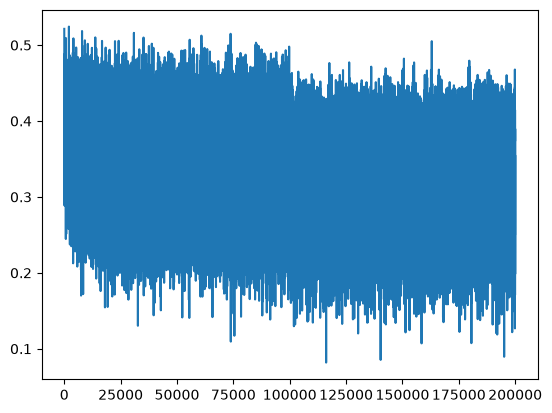

In [41]:
plt.plot(lossi)

Here you can see the beginning of the graph is not like a hockey stick anymore, which means that the initialization is normal, and we do not get those easy gain at the beginning of the training. 

In [42]:
split_loss('train')
split_loss('val')

train 2.069589138031006
val 2.131074905395508


# second issue: activation of the hidden layer

In [56]:
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embd),               generator = g)
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g) 
b1 = torch.randn(n_hidden,                          generator = g)
W2 = torch.randn((n_hidden, vocab_size),            generator = g) * 0.01
b2 = torch.randn(vocab_size,                        generator = g) * 0
parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
    p.requires_grad = True

11897


In [57]:
# hyperparameters
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construction
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X, Y

    # forward pass
    emb = C[Xb] # embed the characters into vectors
    embcat = emb.view(emb.shape[0], -1) # concatenate the embedding vectors
    hpreact = embcat @ W1 + b1 # hidden layer pre-activation
    h = torch.tanh(hpreact) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss function

    # back propogation
    for parameter in parameters:
        parameter.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for parameter in parameters:
        parameter.data -= lr * parameter.grad

    # tract stats
    if i == 0:
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    if (i+1) % 10000 == 0: # print loss function value once in a while
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

    break # we put a break here just to check the loss upon initialization

      1/ 200000: 3.3221


In [58]:
h

tensor([[ 0.8100, -0.8997, -0.9993,  ..., -0.9097, -1.0000,  1.0000],
        [-1.0000, -0.9571, -0.7145,  ...,  0.4898,  0.9090,  0.9937],
        [ 0.9983, -0.3340,  1.0000,  ...,  0.9443,  0.9905,  1.0000],
        ...,
        [-1.0000,  0.9604, -0.1418,  ..., -0.1266,  1.0000,  1.0000],
        [-1.0000, -0.4385, -0.8882,  ..., -0.3316,  0.9995,  1.0000],
        [-1.0000,  0.9604, -0.1418,  ..., -0.1266,  1.0000,  1.0000]],
       grad_fn=<TanhBackward0>)

(array([2069.,  144.,  106.,   82.,   59.,   56.,   43.,   31.,   43.,
          26.,   16.,   38.,   16.,   32.,   24.,   14.,   28.,   27.,
          26.,   19.,   24.,   26.,   30.,   14.,   19.,   19.,   22.,
          26.,   18.,   12.,   10.,   33.,   27.,   32.,   17.,   24.,
          30.,   22.,   26.,   29.,   26.,   40.,   29.,   41.,   49.,
          64.,   62.,  100.,  188., 2442.]),
 array([-1.  , -0.96, -0.92, -0.88, -0.84, -0.8 , -0.76, -0.72, -0.68,
        -0.64, -0.6 , -0.56, -0.52, -0.48, -0.44, -0.4 , -0.36, -0.32,
        -0.28, -0.24, -0.2 , -0.16, -0.12, -0.08, -0.04,  0.  ,  0.04,
         0.08,  0.12,  0.16,  0.2 ,  0.24,  0.28,  0.32,  0.36,  0.4 ,
         0.44,  0.48,  0.52,  0.56,  0.6 ,  0.64,  0.68,  0.72,  0.76,
         0.8 ,  0.84,  0.88,  0.92,  0.96,  1.  ]),
 <BarContainer object of 50 artists>)

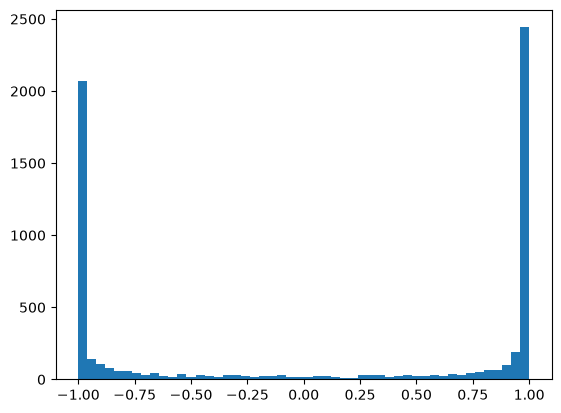

In [59]:
plt.hist(h.view(-1).tolist(), 50) # visualize the distribution of the h value after activation

Obviously, most of the h after activation is clustered around -1 and 1, and the reason behind can be found by inspecting the distribution of hpreact (before activation): **The distribution is too broad**

(array([  2.,   2.,   1.,   4.,   2.,   4.,   6.,  15.,   5.,  25.,  32.,
         49.,  56.,  59.,  92., 119., 134., 197., 195., 221., 257., 275.,
        297., 341., 353., 375., 369., 349., 358., 362., 271., 312., 229.,
        206., 190., 167.,  87., 111.,  72.,  55.,  41.,  22.,  23.,  18.,
         17.,   8.,   5.,   7.,   2.,   1.]),
 array([-19.05793762, -18.31571915, -17.57350067, -16.8312822 ,
        -16.08906372, -15.34684525, -14.60462677, -13.86240829,
        -13.12018982, -12.37797134, -11.63575287, -10.89353439,
        -10.15131592,  -9.40909744,  -8.66687897,  -7.92466049,
         -7.18244202,  -6.44022354,  -5.69800507,  -4.95578659,
         -4.21356812,  -3.47134964,  -2.72913116,  -1.98691269,
         -1.24469421,  -0.50247574,   0.23974274,   0.98196121,
          1.72417969,   2.46639816,   3.20861664,   3.95083511,
          4.69305359,   5.43527206,   6.17749054,   6.91970901,
          7.66192749,   8.40414597,   9.14636444,   9.88858292,
         10.630801

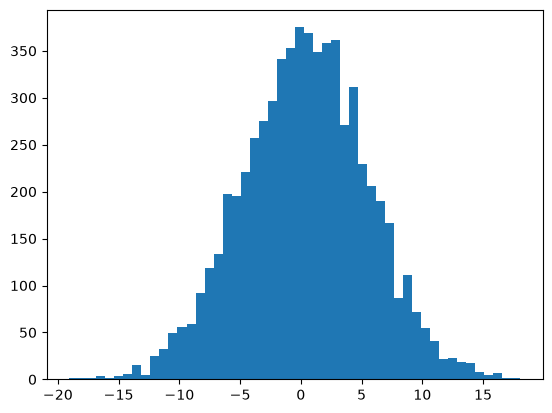

In [60]:
plt.hist(hpreact.view(-1).tolist(), 50)

The reason why this is problem is that when the hpreact is too far away from zero, the result of its grad when doing back propogation would be virtually zero (look at the derivative formula for tanh). As a result, the model will think that changing the weights affect the hpreact too far from 0 will have no effect on the h (after activation). 

here we can try to see how many of the h after activation is so extreme that its abs is beyond 0.99. 

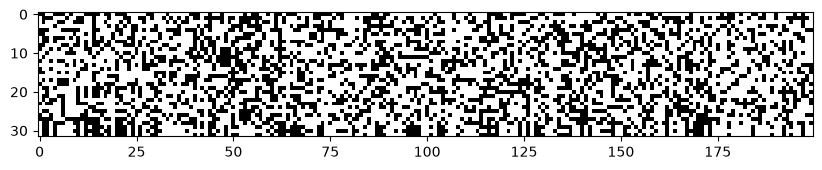

In [61]:
plt.figure(figsize={20, 10})
plt.imshow(h.abs() > 0.99, cmap = 'gray', interpolation = 'nearest')
# h.abs() is a boolean tensor, and the grid is going to be white if it is true and black if false


Since the majority of the graph is white, we know that a lot of h value is very inactive, and on a flat tail. and for almost all of the the backward gradient will get destroyed. 

If we ever have a column that is completely white, then we will have a "dead neuron" since it is very hard to change the value of this column, after all, the h is never in the activated region of the tanh. **It will never learn**

Luckily, that is not the case here. 

And that is also a problem of a learning rate too big, since the step can just push h over the inactivated region and kill it, and chance is that it will just remain dead there in the following iteration of fitting, just like a person suffering from permanent brain damage. 

There are some activation functions that can fix the problem, like leaky ReLU, and ELU, since their solve are never really zero.

![activation functions](act_func.webp)

As seen, the problem is actually just that the hpreact are too far from 0, so we just need to make it so that the values are closer to zero, which can be done by modify W1 and b1. 

For W1, we can just multiply it by 0.2, and for b1 we multiply it by 0.01: the reason why we do not just put b1 altogether to 0 is that we want to give it a little variation and diversity instead of just making it to 0. 

In [67]:
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embd),               generator = g)
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g) * 0.2
b1 = torch.randn(n_hidden,                          generator = g) * 0.01
W2 = torch.randn((n_hidden, vocab_size),            generator = g) * 0.01
b2 = torch.randn(vocab_size,                        generator = g) * 0
parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
    p.requires_grad = True

11897


In [68]:
# hyperparameters
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construction
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X, Y

    # forward pass
    emb = C[Xb] # embed the characters into vectors
    embcat = emb.view(emb.shape[0], -1) # concatenate the embedding vectors
    hpreact = embcat @ W1 + b1 # hidden layer pre-activation
    h = torch.tanh(hpreact) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss function

    # back propogation
    for parameter in parameters:
        parameter.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for parameter in parameters:
        parameter.data -= lr * parameter.grad

    # tract stats
    if i == 0:
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    if (i+1) % 10000 == 0: # print loss function value once in a while
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

    break # we put a break here just to check the loss upon initialization

      1/ 200000: 3.3135


And that seems to be able to fix the problem

(array([143., 172., 172., 161., 142., 151., 133., 116., 116., 143.,  95.,
        104., 126., 111., 119.,  91.,  86.,  90., 115., 100., 112., 122.,
        111.,  77., 103., 119., 100., 106.,  91.,  90., 117., 114., 116.,
        115., 107., 131., 111., 109., 114., 118., 142., 127., 162., 169.,
        152., 197., 184., 192., 208., 198.]),
 array([-9.98924255e-01, -9.58988956e-01, -9.19053657e-01, -8.79118358e-01,
        -8.39183059e-01, -7.99247760e-01, -7.59312460e-01, -7.19377161e-01,
        -6.79441862e-01, -6.39506563e-01, -5.99571264e-01, -5.59635965e-01,
        -5.19700665e-01, -4.79765366e-01, -4.39830067e-01, -3.99894768e-01,
        -3.59959469e-01, -3.20024170e-01, -2.80088871e-01, -2.40153571e-01,
        -2.00218272e-01, -1.60282973e-01, -1.20347674e-01, -8.04123747e-02,
        -4.04770756e-02, -5.41776419e-04,  3.93935227e-02,  7.93288219e-02,
         1.19264121e-01,  1.59199420e-01,  1.99134719e-01,  2.39070019e-01,
         2.79005318e-01,  3.18940617e-01,  3.58875

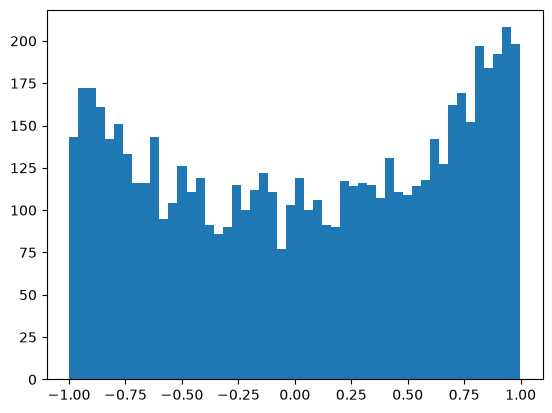

In [70]:
plt.hist(h.view(-1).tolist(), 50) # visualize the distribution of the h value after activation

(array([  1.,   2.,   0.,   1.,   5.,   3.,  11.,   6.,  13.,  10.,  25.,
         40.,  40.,  77.,  63., 101., 127., 171., 184., 220., 227., 267.,
        312., 301., 356., 367., 376., 360., 370., 331., 298., 278., 292.,
        242., 191., 167., 137., 104.,  85.,  77.,  41.,  30.,  28.,  20.,
         11.,   7.,  11.,   5.,   2.,   7.]),
 array([-3.76367116, -3.6200974 , -3.47652364, -3.33294988, -3.18937612,
        -3.04580235, -2.90222859, -2.75865483, -2.61508107, -2.47150731,
        -2.32793355, -2.18435979, -2.04078603, -1.89721227, -1.75363851,
        -1.61006474, -1.46649098, -1.32291722, -1.17934346, -1.0357697 ,
        -0.89219594, -0.74862218, -0.60504842, -0.46147466, -0.3179009 ,
        -0.17432714, -0.03075337,  0.11282039,  0.25639415,  0.39996791,
         0.54354167,  0.68711543,  0.83068919,  0.97426295,  1.11783671,
         1.26141047,  1.40498424,  1.548558  ,  1.69213176,  1.83570552,
         1.97927928,  2.12285304,  2.2664268 ,  2.41000056,  2.55357432,
 

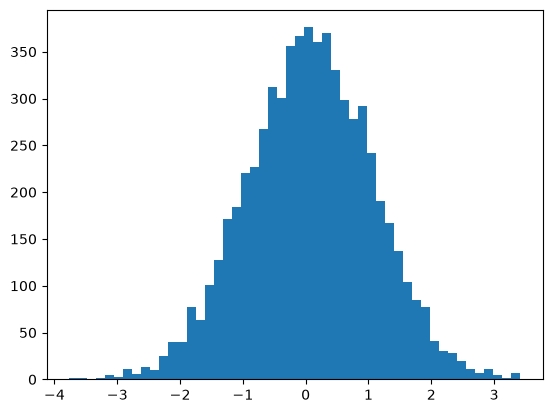

In [71]:
plt.hist(hpreact.view(-1).tolist(), 50) # visualize the distribution of the h value after activation

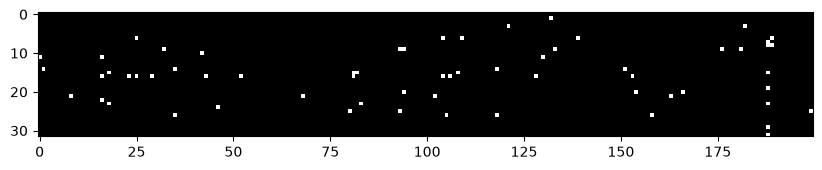

In [72]:
plt.figure(figsize={20, 10})
plt.imshow(h.abs() > 0.99, cmap = 'gray', interpolation = 'nearest')
# h.abs() is a boolean tensor, and the grid is going to be white if it is true and black if false


yay

In [73]:
# full run again
# hyperparameters
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construction
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X, Y

    # forward pass
    emb = C[Xb] # embed the characters into vectors
    embcat = emb.view(emb.shape[0], -1) # concatenate the embedding vectors
    hpreact = embcat @ W1 + b1 # hidden layer pre-activation
    h = torch.tanh(hpreact) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss function

    # back propogation
    for parameter in parameters:
        parameter.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for parameter in parameters:
        parameter.data -= lr * parameter.grad

    # tract stats
    if i == 0:
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    if (i+1) % 10000 == 0: # print loss function value once in a while
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

    # break # we put a break here just to check the loss upon initialization

      1/ 200000: 3.2465
  10000/ 200000: 2.1648
  20000/ 200000: 2.3061
  30000/ 200000: 2.4541
  40000/ 200000: 1.9787
  50000/ 200000: 2.2930
  60000/ 200000: 2.4232
  70000/ 200000: 2.0680
  80000/ 200000: 2.3095
  90000/ 200000: 2.1207
 100000/ 200000: 1.8269
 110000/ 200000: 2.2052
 120000/ 200000: 1.9796
 130000/ 200000: 2.3947
 140000/ 200000: 2.1000
 150000/ 200000: 2.1949
 160000/ 200000: 1.8619
 170000/ 200000: 1.7810
 180000/ 200000: 1.9673
 190000/ 200000: 1.8295
 200000/ 200000: 2.3023


In [74]:
split_loss('train')
split_loss('val')

train 2.035708427429199
val 2.1029491424560547


loss log:

before:
train 2.1264491081237793
val 2.169877767562866

solving first issue: 
train 2.069589138031006
val 2.131074905395508

solving second issue: 
train 2.035708427429199
val 2.1029491424560547

# third issue: the way to get the magical number (0,2, 0.01, 0.01, 0.1) that gives a good initial parameters that even some large neural network allows. 

In [ ]:
x = torch.randn(1000, 10)
w = torch.randn(10, 200)
y = 